# 02 - Error analysis (run after `python -m src.train`)
Takes ~100 misclassified test reviews, exports them for hand-categorizing, then counts the categories.

**Categories:** negation, sarcasm, mixed sentiment, rating-text mismatch (label noise), very short text, shipping vs product complaint, non-English leakage, other.

Note: the test split is reproduced with the same seed as `train.py`; it matches only if silver has not been regenerated since training.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from src.common.config import load_config, data_path, results_dir
from src.common.spark_session import get_spark

cfg = load_config()
spark = get_spark("notebook", cfg)

26/11/22 05:22:49 WARN Utils: Your hostname, DESKTOP-23Q32ON resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/22 05:22:49 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/22 05:22:49 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
from pyspark.ml import PipelineModel
from src.train import split

silver = spark.read.parquet(data_path(cfg, "silver", "reviews"))
_, test = split(silver, cfg)
model = PipelineModel.load(data_path(cfg, "models", "scoring_pipeline"))
scored = model.transform(test).select("review_id", "rating", "label", "prediction", "text_clean")
wrong = scored.filter(F.col("label") != F.col("prediction"))
print("test rows:", test.count(), "| misclassified:", wrong.count())

26/11/22 05:22:59 WARN DAGScheduler: Broadcasting large task binary with size 3.7 MiB
[Stage 26:==================================================>       (7 + 1) / 8]

test rows: 180945 | misclassified: 8199


## Export ~100 misclassified reviews for labeling
Open the CSV, fill the `category` column (use the categories above), save as CSV, then run the next cell.

In [3]:
n_wrong = wrong.count()
sample = wrong.sample(False, min(1.0, 150 / max(n_wrong, 1)), 42).limit(100).toPandas()
sample["category"] = ""
out = results_dir(cfg) / "error_analysis"
out.mkdir(parents=True, exist_ok=True)
dest = out / "misclassified_sample.csv"
if dest.exists():
    print("already exists, not overwriting (it may contain your labels):", dest)
else:
    sample.to_csv(dest, index=False); print("wrote", dest, len(sample), "rows")

26/11/22 05:23:04 WARN DAGScheduler: Broadcasting large task binary with size 3.7 MiB
26/11/22 05:23:08 WARN DAGScheduler: Broadcasting large task binary with size 3.7 MiB
26/11/22 05:23:11 WARN DAGScheduler: Broadcasting large task binary with size 3.7 MiB
[Stage 33:>                                                         (0 + 2) / 2]

already exists, not overwriting (it may contain your labels): /home/mdanas/sentiment-bda/results/error_analysis/misclassified_sample.csv


## Count categories (after you have filled `category`)

unlabeled rows: 0
category
mixed sentiment                  54
rating-text mismatch             17
other                            11
negation                         10
very short text                   5
shipping vs product complaint     2
non-English leakage               1
Name: count, dtype: int64


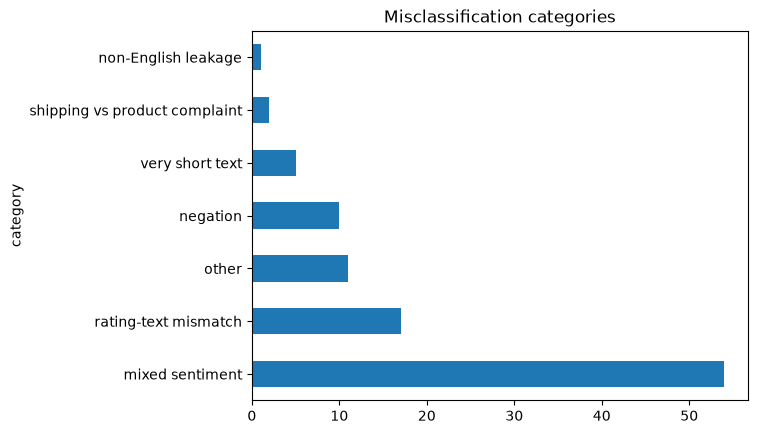

In [4]:
labeled = pd.read_csv(results_dir(cfg) / "error_analysis" / "misclassified_sample.csv")
labeled["category"] = labeled["category"].fillna("").str.strip()
print("unlabeled rows:", (labeled["category"] == "").sum())
counts = labeled[labeled["category"] != ""]["category"].value_counts()
print(counts); counts.plot.barh(title="Misclassification categories"); plt.show()

## Examples per category

In [5]:
for cat, g in labeled[labeled["category"] != ""].groupby("category"):
    print(f"\n== {cat} ({len(g)})")
    for _, r in g.head(3).iterrows():
        print(f"  rating={r['rating']} predicted={r['prediction']} | {str(r['text_clean'])[:200]}")


== mixed sentiment (54)
  rating=5.0 predicted=0.0 | authentic. i seen bad reviews but people have to learn how to buy authentic products if you buy products sold and ship by amazon you can be 100 sure that it will be authentic
  rating=5.0 predicted=0.0 | it's very bright. it's cool didn't realize that it doesn't work with plug
  rating=4.0 predicted=0.0 | gets very hot. this charger gets hot while in use. i tried to contact the seller about the problem but my message couldn't be delivered for whatever reason. very frustrating update changed review from

== negation (10)
  rating=5.0 predicted=0.0 | good fit and appearance. fit well, clear. functional. durability can not state yet, had it for 7 days, have not dropped yet to know if durable or not. otherwise all else concerning this case is as adv
  rating=5.0 predicted=0.0 | it fits!. i purchased this phone case and wondered if it would actually fit my husband's luna pro. we had purchased one at a chain store and the one the clerk sa

In [6]:
spark.stop()